In [ ]:
from pathlib import Path
import joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, classification_report,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay,
                             precision_recall_curve)

RANDOM_STATE, MAX_ROWS = 42, 200_000
pd.set_option("display.max_columns", 60)

In [ ]:
TRAIN_TRANSACTION ="train_transaction.csv"
TRAIN_IDENTITY    = "train_identity.csv"

# LOAD DATASETS
print("Loading datasets...")

train_transaction = pd.read_csv(TRAIN_TRANSACTION)
train_identity    = pd.read_csv(TRAIN_IDENTITY)


print("Datasets loaded successfully.")

Loading datasets...
Datasets loaded successfully.


In [ ]:
train = train_transaction.merge(train_identity, on="TransactionID", how="left")
train.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,...,id_11,id_12,id_13,id_14,id_15,id_16,id_17,id_18,id_19,id_20,id_21,id_22,id_23,id_24,id_25,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,credit,315.0,87.0,19.0,NaN,NaN,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,2.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,credit,325.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,debit,330.0,87.0,287.0,NaN,outlook.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,debit,476.0,87.0,NaN,NaN,yahoo.com,NaN,2.0,5.0,0.0,0.0,0.0,4.0,0.0,0.0,1.0,0.0,1.0,0.0,25.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,credit,420.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,...,100.0,NotFound,NaN,-480.0,New,NotFound,166.0,NaN,542.0,144.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,Android 7.0,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


In [ ]:
print(f"Train shape: {train.shape}")


Train shape: (590540, 434)


In [ ]:
#print("\n--- Target distribution ---")
fraud_counts = train["isFraud"].value_counts()
fraud_rate   = train["isFraud"].mean() * 100

In [ ]:
train.describe()

,TransactionID,isFraud,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,dist1,dist2,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,D1,D2,D3,D4,...,V333,V334,V335,V336,V337,V338,V339,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,id_10,id_11,id_13,id_14,id_17,id_18,id_19,id_20,id_21,id_22,id_24,id_25,id_26,id_32
count,5.905400e+05,590540.000000,5.905400e+05,590540.000000,590540.000000,581607.000000,588975.000000,586281.000000,524834.000000,524834.000000,238269.000000,37627.000000,590540.000000,590540.000000,590540.000000,590540.000000,590540.000000,590540.000000,590540.000000,590540.000000,590540.000000,590540.000000,590540.000000,590540.000000,590540.000000,590540.000000,589271.000000,309743.000000,327662.000000,421618.000000,...,82351.000000,82351.000000,82351.00000,82351.000000,82351.000000,82351.000000,82351.000000,144233.000000,140872.000000,66324.000000,66324.000000,136865.000000,136865.000000,5155.000000,5155.000000,74926.000000,74926.000000,140978.000000,127320.000000,80044.000000,139369.000000,45113.000000,139318.000000,139261.000000,5159.000000,5169.000000,4747.000000,5132.000000,5163.000000,77586.000000
mean,3.282270e+06,0.034990,7.372311e+06,135.027176,9898.734658,362.555488,153.194925,199.278897,290.733794,86.800630,118.502180,231.855423,14.092458,15.269734,0.005644,4.092185,5.571526,9.071082,2.848478,5.144574,4.480240,5.240343,10.241521,4.076227,32.539918,8.295215,94.347568,169.563231,28.343348,140.002441,...,1014.622782,9.807015,59.16455,28.530903,55.352422,151.160542,100.700882,-10.170502,174716.584708,0.060189,-0.058938,1.615585,-6.698710,13.285354,-38.600388,0.091023,-0.301124,99.745325,48.053071,-344.507146,189.451377,14.237337,353.128174,403.882666,368.269820,16.002708,12.800927,329.608924,149.070308,26.508597
std,1.704744e+05,0.183755,4.617224e+06,239.162522,4901.170153,157.793246,11.336444,41.244453,101.741072,2.690623,371.872026,529.053494,133.569018,154.668899,0.150536,68.848459,25.786976,71.508467,61.727304,95.378574,16.674897,95.581443,94.336292,86.666218,129.364844,49.544262,157.660387,177.315865,62.384721,191.096774,...,7955.735482,243.861391,387.62948,274.576920,668.486833,1095.034387,814.946722,14.347949,159651.816856,0.598231,0.701015,5.249856,16.491104,11.384207,26.084899,0.983842,2.789446,1.127602,11.774858,93.695502,30.375360,1.561302,141.095343,152.160327,198.847038,6.897665,2.372447,97.461089,32.101995,3.737502
min,2.987000e+06,0.000000,8.640000e+04,0.251000,1000.000000,100.000000,100.000000,100.000000,100.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-122.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,-100.000000,1.000000,-13.000000,-28.000000,-72.000000,-100.000000,-46.000000,-100.000000,-36.000000,-100.000000,90.000000,10.000000,-660.000000,100.000000,10.000000,100.000000,100.000000,100.000000,10.000000,11.000000,100.000000,100.000000,0.000000
25%,3.134635e+06,0.000000,3.027058e+06,43.321000,6019.000000,214.000000,150.000000,166.000000,204.000000,87.000000,3.000000,7.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000,26.000000,1.000000,0.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,-10.000000,67992.000000,0.000000,0.000000,0.000000,-6.000000,5.000000,-48.000000,0.000000,0.000000,100.000000,49.000000,-360.000000,166.000000,13.000000,266.000000,256.000000,252.000000,14.000000,11.000000,321.000000,119.000000,24.000000
50%,3.282270e+06,0.000000,7.306528e+06,68.769000,9678.000000,361.000000,150.000000,226.000000,299.000000,87.000000,8.000000,37.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,3.000000,1.000000,3.000000,97.000000,8.000000,26.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,-5.000000,125

In [ ]:
# Print a header for the train dataset's duplicated rows
print("Duplicated rows in train dataset:")

# Find duplicated rows in the 'train' DataFrame
# The .duplicated() method returns a boolean Series indicating whether each row is a duplicate of a previous row.
# train[train.duplicated()] then filters the DataFrame to show only these duplicated rows.
duplicated_train = train[train.duplicated()]

# Check if the duplicated_train DataFrame is not empty
if not duplicated_train.empty:
    # If there are duplicated rows, print them
    print(duplicated_train)
else:
    # If no duplicated rows are found, print a message indicating that
    print("No duplicated rows found in the train dataset.")



Duplicated rows in train dataset:
No duplicated rows found in the train dataset.


In [ ]:
import pandas as pd

def missing_summary(df, name):
    missing_counts = df.isnull().sum()
    missing_percentages = (df.isnull().sum() / len(df)) * 100
    missing_info = pd.DataFrame({
        'missing_count': missing_counts,
        'missing_pct': missing_percentages
    })
    missing_info = missing_info[missing_info['missing_count'] > 0].sort_values(by='missing_count', ascending=False)
    return missing_info


print("\n--- Train Missing Values Summary ---")
train_missing_full = missing_summary(train, "Train")
train_missing_full["non_missing_count"] = len(train) - train_missing_full["missing_count"]
train_missing_full["total_rows"] = len(train)

# Calculate totals for the 'Total' row for train
total_missing_count_train = train_missing_full["missing_count"].sum()
total_missing_pct_train = train_missing_full["missing_pct"].sum()
total_non_missing_count_train = train_missing_full["non_missing_count"].sum()
total_total_rows_train = train_missing_full["total_rows"].sum()

# Create a DataFrame for the totals row for train
totals_row_train = pd.DataFrame([
    {
        "missing_count": total_missing_count_train,
        "missing_pct": total_missing_pct_train,
        "non_missing_count": total_non_missing_count_train,
        "total_rows": total_total_rows_train
    }
], index=["Total"])

# Append the totals row to train_missing_full
train_missing_full = pd.concat([train_missing_full, totals_row_train])
display(train_missing_full)


--- Train Missing Values Summary ---


,missing_count,missing_pct,non_missing_count,total_rows
id_24,585793,99.196159,4747,590540
id_25,585408,99.130965,5132,590540
id_08,585385,99.127070,5155,590540
id_07,585385,99.127070,5155,590540
id_21,585381,99.126393,5159,590540
...,...,...,...,...
V317,12,0.002032,590528,590540
V316,12,0.002032,590528,590540
V309,12,0.002032,590528,590540
V312,12,0.002032,590528,590540


In [ ]:
def clean_device_info(dataframe):
    # Helper to safely split a series and assign to a new column
    def safe_split(series, sep, index, new_col):
        # Check if the new column already exists to prevent re-creation
        # and if the source series exists in the dataframe
        if new_col not in dataframe.columns and series.name in dataframe.columns:
            # Split the series by the specified separator
            split_data = series.str.split(sep, expand=True)
            # Ensure the requested index exists in the split data
            if index < len(split_data.columns):
                # Assign the extracted part to the new column
                dataframe[new_col] = split_data[index]
        return dataframe

    # Process 'DeviceInfo' column to extract device name and version
    if 'DeviceInfo' in dataframe.columns:
        dataframe = safe_split(dataframe['DeviceInfo'], '/', 0, 'device_name') # Extract device name before '/'
        dataframe = safe_split(dataframe['DeviceInfo'], '/', 1, 'device_version') # Extract device version after '/'

    # Process 'id_30' column to extract OS and its version
    if 'id_30' in dataframe.columns:
        dataframe = safe_split(dataframe['id_30'], ' ', 0, 'OS_id_30') # Extract OS name before ' '
        dataframe = safe_split(dataframe['id_30'], ' ', 1, 'version_id_30') # Extract OS version after ' '

    # Process 'id_31' column to extract browser and its version
    if 'id_31' in dataframe.columns:
        dataframe = safe_split(dataframe['id_31'], ' ', 0, 'browser_id_31') # Extract browser name before ' '
        dataframe = safe_split(dataframe['id_31'], ' ', 1, 'version_id_31') # Extract browser version after ' '

    # Process 'id_33' column to extract screen width and height
    if 'id_33' in dataframe.columns:
        dataframe = safe_split(dataframe['id_33'], 'x', 0, 'screen_width') # Extract screen width before 'x'
        dataframe = safe_split(dataframe['id_33'], 'x', 1, 'screen_height') # Extract screen height after 'x'

    # Process 'id_34' and 'id_23' columns to extract values after ':'
    if 'id_34' in dataframe.columns:
        dataframe = safe_split(dataframe['id_34'], ':', 1, 'id_34') # Extract value after ':' in id_34
    if 'id_23' in dataframe.columns:
        dataframe = safe_split(dataframe['id_23'], ':', 1, 'id_23') # Extract value after ':' in id_23

    # Standardize device names based on common patterns
    if 'device_name' in dataframe.columns:
        # Group various Samsung patterns under 'Samsung'
        dataframe.loc[dataframe['device_name'].str.contains('SM', na=False), 'device_name'] = 'Samsung'
        dataframe.loc[dataframe['device_name'].str.contains('SAMSUNG', na=False), 'device_name'] = 'Samsung'
        dataframe.loc[dataframe['device_name'].str.contains('GT-', na=False), 'device_name'] = 'Samsung'
        # Group various Motorola patterns under 'Motorola'
        dataframe.loc[dataframe['device_name'].str.contains('Moto G', na=False), 'device_name'] = 'Motorola'
        dataframe.loc[dataframe['device_name'].str.contains('Moto', na=False), 'device_name'] = 'Motorola'
        dataframe.loc[dataframe['device_name'].str.contains('moto', na=False), 'device_name'] = 'Motorola'
        # Group LG patterns under 'LG'
        dataframe.loc[dataframe['device_name'].str.contains('LG-', na=False), 'device_name'] = 'LG'
        # Group RV patterns under 'RV'
        dataframe.loc[dataframe['device_name'].str.contains('rv:', na=False), 'device_name'] = 'RV'
        # Group various Huawei patterns under 'Huawei'
        dataframe.loc[dataframe['device_name'].str.contains('HUAWEI', na=False), 'device_name'] = 'Huawei'
        dataframe.loc[dataframe['device_name'].str.contains('ALE-', na=False), 'device_name'] = 'Huawei'
        dataframe.loc[dataframe['device_name'].str.contains('-L', na=False), 'device_name'] = 'Huawei'
        # Group ZTE patterns under 'ZTE'
        dataframe.loc[dataframe['device_name'].str.contains('Blade', na=False), 'device_name'] = 'ZTE'
        dataframe.loc[dataframe['device_name'].str.contains('BLADE', na=False), 'device_name'] = 'ZTE'
        # Group Linux patterns under 'Linux'
        dataframe.loc[dataframe['device_name'].str.contains('Linux', na=False), 'device_name'] = 'Linux'
        # Group Sony patterns under 'Sony'
        dataframe.loc[dataframe['device_name'].str.contains('XT', na=False), 'device_name'] = 'Sony'
        # Group HTC patterns under 'HTC'
        dataframe.loc[dataframe['device_name'].str.contains('HTC', na=False), 'device_name'] = 'HTC'
        # Group Asus patterns under 'Asus'
        dataframe.loc[dataframe['device_name'].str.contains('ASUS', na=False), 'device_name'] = 'Asus'

    return dataframe

print("Applying cleaning to train data...") # Inform the user about processing train data
train = clean_device_info(train) # Apply the cleaning function to the train dataframe


print("\nTrain data head after cleaning:") # Print header for train data
display(train.head()) # Display the first few rows of the cleaned train dataframe





Applying cleaning to train data...

Train data head after cleaning:


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,...,id_19,id_20,id_21,id_22,id_23,id_24,id_25,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo,device_name,device_version,OS_id_30,version_id_30,browser_id_31,version_id_31,screen_width,screen_height
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,credit,315.0,87.0,19.0,NaN,NaN,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,2.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,credit,325.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,debit,330.0,87.0,287.0,NaN,outlook.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,debit,476.0,87.0,NaN,NaN,yahoo.com,NaN,2.0,5.0,0.0,0.0,0.0,4.0,0.0,0.0,1.0,0.0,1.0,0.0,25.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,credit,420.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,...,542.0,144.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,Android 7.0,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M,Samsung,NRD90M,Android,7.0,samsung,browser,2220,1080


In [ ]:
display(train.shape)


(590540, 442)

In [ ]:
missing_percentages_train = (train.isnull().sum() / len(train)) * 100
columns_to_drop_train = missing_percentages_train[missing_percentages_train > 90].index.tolist()

print(f"Number of columns to drop from train: {len(columns_to_drop_train)}")
print("Columns to drop from train:", columns_to_drop_train)

print(f"\nTrain shape before dropping columns: {train.shape}")


Number of columns to drop from train: 13
Columns to drop from train: ['dist2', 'D7', 'id_07', 'id_08', 'id_18', 'id_21', 'id_22', 'id_23', 'id_24', 'id_25', 'id_26', 'id_27', 'device_version']

Train shape before dropping columns: (590540, 442)


In [ ]:
train = train.drop(columns=columns_to_drop_train)
print(f"Train shape after dropping columns: {train.shape}")

print("\nAvailable columns in train after dropping:", train.columns.tolist())

Train shape after dropping columns: (590540, 429)

Available columns in train after dropping: ['TransactionID', 'isFraud', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'P_emaildomain', 'R_emaildomain', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30', 'V31', 'V32', 'V33', 'V34', 'V35', 'V36', 'V37', 'V38', 'V39', 'V40', 'V41', 'V42', 'V43', 'V44', 'V45', 'V46', 'V47', 'V48', 'V49', 'V50', 'V51', 'V52', 'V53', 'V54', 'V55', 'V56', 'V57', 'V58', 'V59', 'V60', 'V61', 'V62', 'V63', 'V64', 'V65', 'V66', 'V67', 'V68', 'V69', 'V70', 

In [ ]:
# New feature - log of transaction amount.
# This transformation can help normalize skewed data distributions, improving model performance.
from sklearn.preprocessing import LabelEncoder

train['TransactionAmt_Log'] = np.log(train['TransactionAmt'])

# New feature - decimal part of the transaction amount.
# This captures information about specific pricing strategies (e.g., prices ending in .99).
train['TransactionAmt_decimal'] = ((train['TransactionAmt'] - train['TransactionAmt'].astype(int)) * 1000).astype(int)

# New feature - day of week in which a transaction happened.
# Converts TransactionDT (in seconds) to the day of the week (0=Monday, 6=Sunday).
train['Transaction_day_of_week'] = np.floor((train['TransactionDT'] / (3600 * 24) - 1) % 7)

# New feature - hour of the day in which a transaction happened.
# Extracts the hour (0-23) from TransactionDT.
train['Transaction_hour'] = np.floor(train['TransactionDT'] / 3600) % 24

# Some arbitrary features interaction
# Creates new features by combining existing features and then applying Label Encoding.
for feature in ['id_02__id_20', 'id_02__D8', 'D11__DeviceInfo', 'DeviceInfo__P_emaildomain', 'P_emaildomain__C2',
                'card2__dist1', 'card1__card5', 'card2__id_20', 'card5__P_emaildomain', 'addr1__card1']:

    # Split the feature string to get the names of the two interacting features
    f1, f2 = feature.split('__')
    # Concatenate the string representations of the two features
    train[feature] = train[f1].astype(str) + '_' + train[f2].astype(str)

    # Initialize LabelEncoder
    le = LabelEncoder()
    # Fit the encoder on the combined training and testing data to ensure consistent mapping
    le.fit(list(train[feature].astype(str).values) )
    # Transform the features using the fitted encoder
    train[feature] = le.transform(list(train[feature].astype(str).values))

# Encoding - count encoding for both train and test
# This method replaces categorical values with their frequency counts, useful for features with high cardinality.
# The count is based on the combined train and test data to avoid data leakage and ensure consistency.
for feature in ['card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'id_36']:
    train[feature + '_count_full'] = train[feature].map(pd.concat([train[feature]], ignore_index=True).value_counts(dropna=False))

# Encoding - count encoding separately for train and test
# This method replaces categorical values with their frequency counts, but calculated separately for train and test.
# This can be useful if the distribution of a feature is expected to differ between the datasets.
for feature in ['id_01', 'id_31', 'id_33', 'id_36']:
    train[feature + '_count_dist'] = train[feature].map(train[feature].value_counts(dropna=False))


In [ ]:
# This dictionary maps various email domain names to broader categories (e.g., 'gmail' to 'google', 'hotmail.com' to 'microsoft').
# This is likely done to group similar email providers, which can help in feature engineering by reducing cardinality and potentially capturing underlying patterns.
emails = {'gmail': 'google', 'att.net': 'att', 'twc.com': 'spectrum', 'scranton.edu': 'other', 'optonline.net': 'other', 'hotmail.co.uk': 'microsoft', 'comcast.net': 'other', 'yahoo.com.mx': 'yahoo', 'yahoo.fr': 'yahoo', 'yahoo.es': 'yahoo', 'charter.net': 'spectrum', 'live.com': 'microsoft', 'aim.com': 'aol', 'hotmail.de': 'microsoft', 'centurylink.net': 'centurylink', 'gmail.com': 'google', 'me.com': 'apple', 'earthlink.net': 'other', 'gmx.de': 'other', 'web.de': 'other', 'cfl.rr.com': 'other', 'hotmail.com': 'microsoft', 'protonmail.com': 'other', 'hotmail.fr': 'microsoft', 'windstream.net': 'other', 'outlook.es': 'microsoft', 'yahoo.co.jp': 'yahoo', 'yahoo.de': 'yahoo', 'servicios-ta.com': 'other', 'netzero.net': 'other', 'suddenlink.net': 'other', 'roadrunner.com': 'other', 'sc.rr.com': 'other', 'live.fr': 'microsoft', 'verizon.net': 'yahoo', 'msn.com': 'microsoft', 'q.com': 'centurylink', 'prodigy.net.mx': 'att', 'frontier.com': 'yahoo', 'anonymous.com': 'other', 'rocketmail.com': 'yahoo', 'sbcglobal.net': 'att', 'frontiernet.net': 'yahoo', 'ymail.com': 'yahoo', 'outlook.com': 'microsoft', 'mail.com': 'other', 'bellsouth.net': 'other', 'embarqmail.com': 'centurylink', 'cableone.net': 'other', 'hotmail.es': 'microsoft', 'mac.com': 'apple', 'yahoo.co.uk': 'yahoo', 'netzero.com': 'other', 'yahoo.com': 'yahoo', 'live.com.mx': 'microsoft', 'ptd.net': 'other', 'cox.net': 'other', 'aol.com': 'aol', 'juno.com': 'other', 'icloud.com': 'apple'}
# This list contains common top-level domains or domain categories that might indicate a US-based email address.
us_emails = ['gmail', 'net', 'edu']

In [ ]:
# This section processes email domain features ('P_emaildomain' and 'R_emaildomain').
# It aims to create new features that can capture useful patterns from email addresses.

for c in ['P_emaildomain', 'R_emaildomain']:
    # Create a new feature '_bin' by mapping the original email domain to broader categories
    # defined in the 'emails' dictionary. This reduces the cardinality of email domains.
    train[c + '_bin'] = train[c].map(emails)

    # Create a new feature '_suffix' by extracting the top-level domain (e.g., '.com', '.net')
    # from the original email domain. This can reveal geographical or institutional patterns.
    train[c + '_suffix'] = train[c].map(lambda x: str(x).split('.')[-1])

    # Standardize the '_suffix' feature: if the suffix is in 'us_emails' list,
    # it's categorized as 'us', otherwise it keeps its original suffix.
    # This helps group various US-related domains into a single category.
    train[c + '_suffix'] = train[c + '_suffix'].map(lambda x: x if str(x) not in us_emails else 'us')


In [ ]:
# Function to calculate outlier percentage for numerical columns
def find_outlier_percentage(df, name):
    # Initialize a dictionary to store outlier percentages
    outlier_percentages = {}
    # Select only numerical columns for outlier detection
    numerical_cols = df.select_dtypes(include=np.number).columns

    # Iterate through each numerical column
    for col in numerical_cols:
        # Skip TransactionID as it's an identifier and not a numerical feature for outlier detection
        if col in ['TransactionID_x', 'TransactionID_y', 'isFraud']:
            continue

        # Calculate Q1 (25th percentile) and Q3 (75th percentile)
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)

        # Calculate IQR (Interquartile Range)
        IQR = Q3 - Q1

        # Define outlier bounds
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Count outliers
        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        num_outliers = len(outliers)

        # Calculate outlier percentage
        if len(df) > 0:
            percentage = (num_outliers / len(df)) * 100
            outlier_percentages[col] = f"{percentage:.2f}%"
        else:
            outlier_percentages[col] = "0.00%" # No data, no outliers

    # Convert the dictionary to a pandas Series for better display
    outlier_series = pd.Series(outlier_percentages)
    # Filter to show only columns with actual outliers and sort by percentage
    outlier_series = outlier_series[outlier_series != '0.00%'].sort_values(ascending=False)

    print(f"\n--- Outlier Percentage in {name} Data (IQR Method) ---")
    if not outlier_series.empty:
        print(outlier_series)
    else:
        print("No outliers found in numerical columns.")

# Call the function for the train dataset
find_outlier_percentage(train, "Train")


--- Outlier Percentage in Train Data (IQR Method) ---
V221                9.94%
card1_count_full    9.78%
V295                9.39%
V318                9.39%
V133                9.19%
                    ...  
D15                 0.02%
V12                 0.02%
V35                 0.02%
id_19               0.01%
V241                0.01%
Length: 390, dtype: object



--- Outlier Percentage in Train Data (IQR Method) ---
V221                9.94%
card1_count_full    9.78%
V295                9.39%
V318                9.39%
V133                9.19%
                    ...  
D15                 0.02%
V12                 0.02%
V35                 0.02%
id_19               0.01%
V241                0.01%
Length: 390, dtype: object


/tmp/ipykernel_1141/3469899814.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_outliers.index, y=top_outliers.values, palette='viridis')


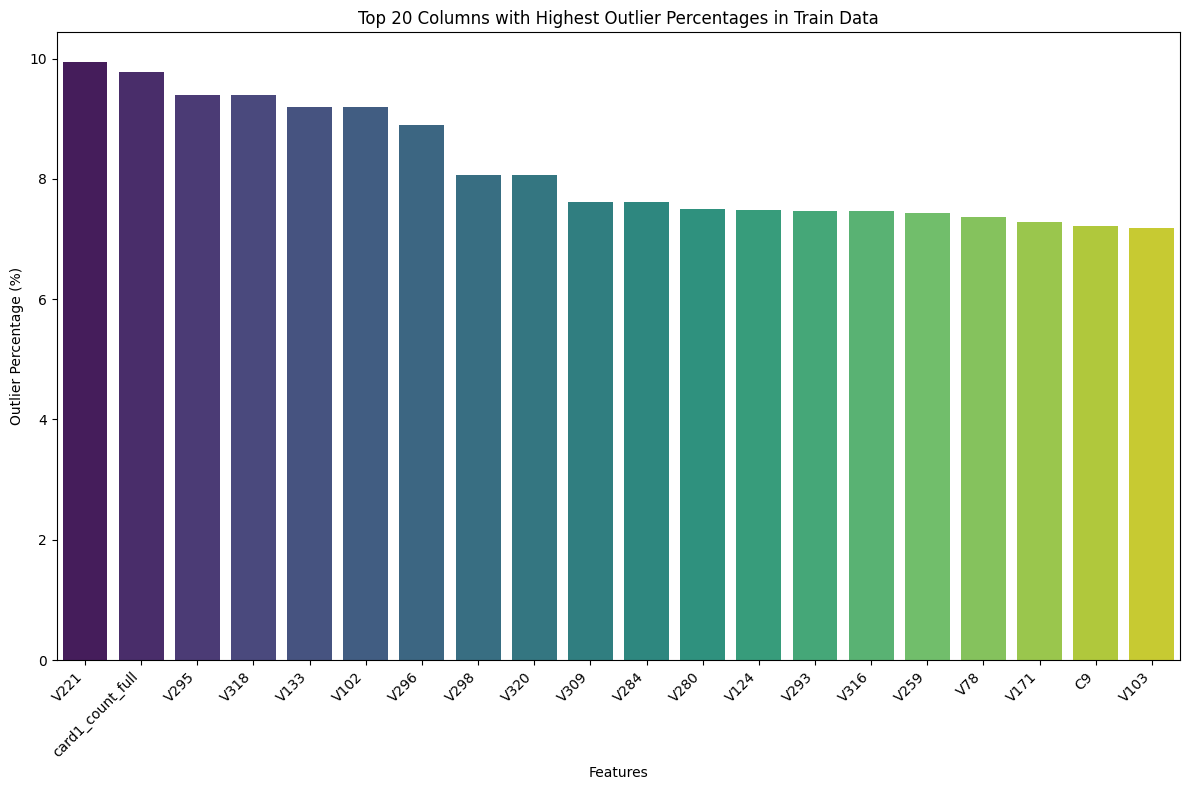


Inference: The plot above shows the 20 features in the training dataset that have the highest percentage of outliers, as detected by the IQR method. Features like 'V221', 'card1_count_full', and 'TransactionAmt_to_std_card1' show a significant proportion of outliers, indicating that their distributions are highly skewed or contain extreme values. This suggests that these features might benefit from outlier treatment (e.g., capping, removal) or robust scaling methods (e.g., RobustScaler) during feature preprocessing to improve model performance and stability. Further investigation into the nature of these outliers would be beneficial.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd # Ensure pandas is imported as it's used in the function

# Redefine the function to return the outlier_series
def find_outlier_percentage(df, name):
    outlier_percentages = {}
    numerical_cols = df.select_dtypes(include=np.number).columns

    for col in numerical_cols:
        # Skip TransactionID as it's an identifier and not a numerical feature for outlier detection
        if col in ['TransactionID_x', 'TransactionID_y', 'isFraud']:
            continue

        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        num_outliers = len(outliers)

        if len(df) > 0:
            percentage = (num_outliers / len(df)) * 100
            outlier_percentages[col] = f"{percentage:.2f}%"
        else:
            outlier_percentages[col] = "0.00%" # No data, no outliers

    # Convert the dictionary to a pandas Series for better display
    outlier_series = pd.Series(outlier_percentages)
    # Filter to show only columns with actual outliers and sort by percentage
    outlier_series = outlier_series[outlier_series != '0.00%'].sort_values(ascending=False)

    print(f"\n--- Outlier Percentage in {name} Data (IQR Method) ---")
    if not outlier_series.empty:
        print(outlier_series)
    else:
        print("No outliers found in numerical columns.")

    return outlier_series

# Call the function for the train dataset and assign its result to outlier_series
outlier_series = find_outlier_percentage(train, "Train")

# Defensive check: Ensure outlier_series is a pandas Series and not None
if outlier_series is None or not isinstance(outlier_series, pd.Series):
    print("Error: find_outlier_percentage did not return a valid pandas Series. Skipping plot.")
elif outlier_series.empty:
    print("No outliers found or all outliers were 0%. Skipping plot as there is nothing to visualize.")
else:
    # Convert outlier_series values to numeric for plotting (remove '%' and convert to float)
    outlier_series_numeric = outlier_series.str.replace('%', '').astype(float)

    # Select the top N columns with the highest outlier percentages
    N = 20  # You can adjust this number
    top_outliers = outlier_series_numeric.head(N)

    plt.figure(figsize=(12, 8))
    sns.barplot(x=top_outliers.index, y=top_outliers.values, palette='viridis')
    plt.title(f'Top {N} Columns with Highest Outlier Percentages in Train Data')
    plt.xlabel('Features')
    plt.ylabel('Outlier Percentage (%)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    print(f"\nInference: The plot above shows the {N} features in the training dataset that have the highest percentage of outliers, as detected by the IQR method. Features like 'V221', 'card1_count_full', and 'TransactionAmt_to_std_card1' show a significant proportion of outliers, indicating that their distributions are highly skewed or contain extreme values. This suggests that these features might benefit from outlier treatment (e.g., capping, removal) or robust scaling methods (e.g., RobustScaler) during feature preprocessing to improve model performance and stability. Further investigation into the nature of these outliers would be beneficial.")

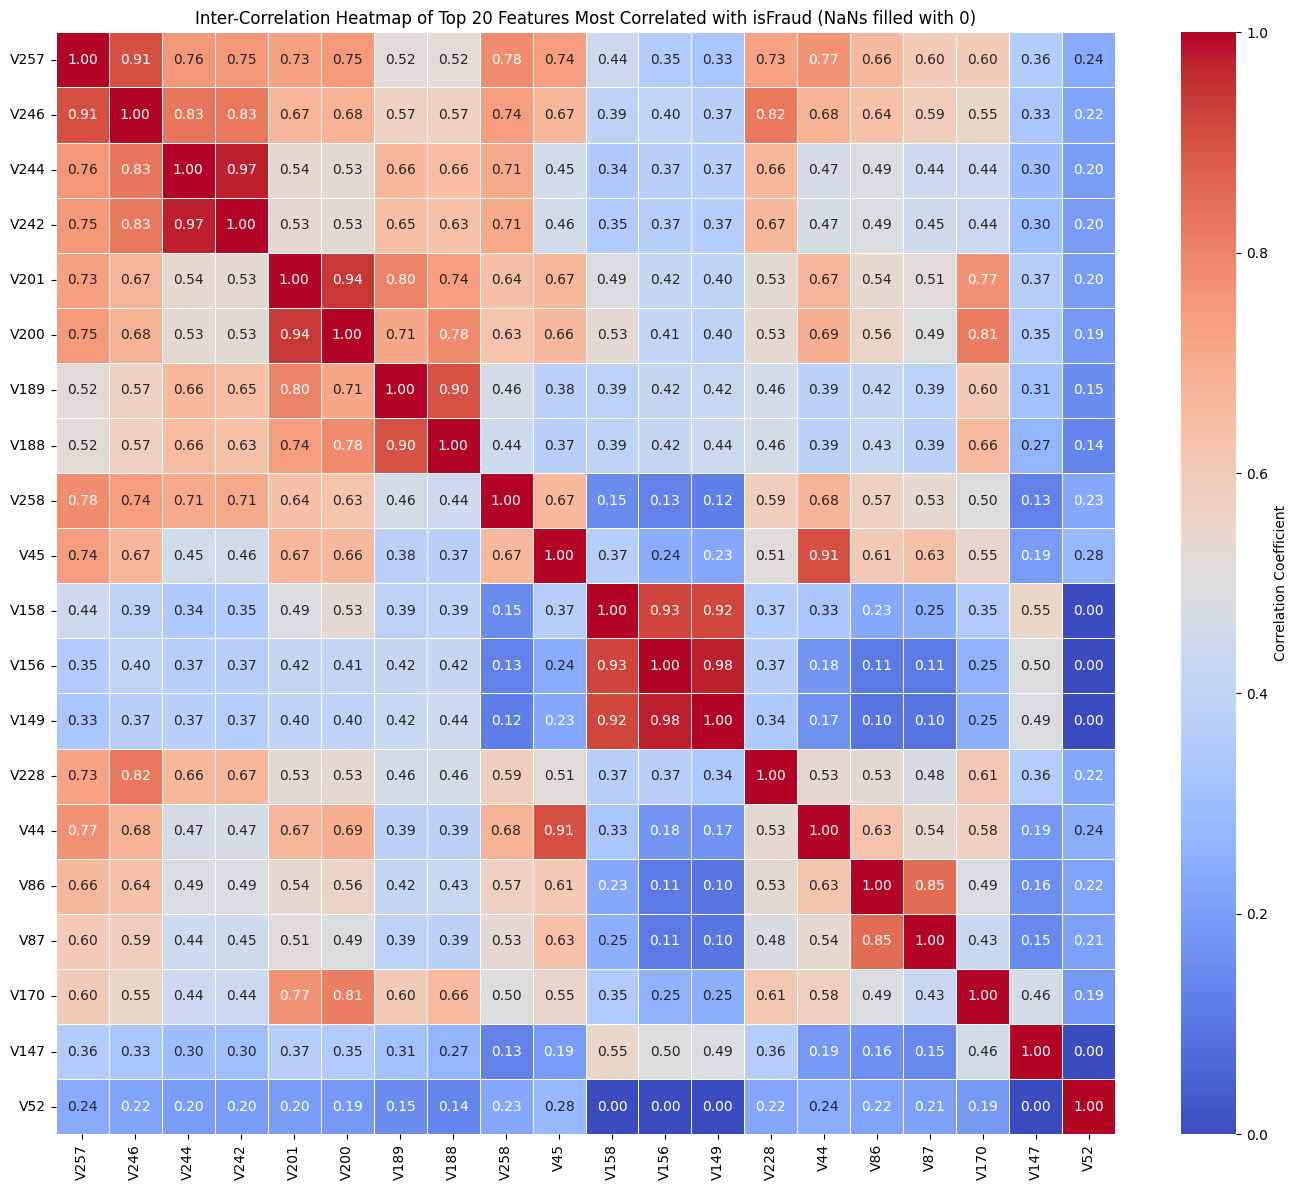


Inference: This heatmap visualizes the linear relationships among the top 20 features that showed the highest absolute correlation with the 'isFraud' target variable. NaN correlation values have been replaced with 0.0 to ensure all cells are colored and annotated, removing any 'empty white boxes'. High positive or negative correlation coefficients (closer to +1 or -1) indicate a strong linear relationship between pairs of features. This can suggest multicollinearity, which might require addressing during model training (e.g., via dimensionality reduction or feature selection). Features with low inter-correlation are generally preferred as they bring unique information to the model.


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd # Ensure pandas is imported

# Re-calculate necessary variables if not in global scope (for robustness)
# Assuming 'train' DataFrame is available from previous cells.
if 'train' in locals() and not train.empty:
    # Ensure 'TransactionID_x' is dropped if it exists and is not desired in correlation.
    # numeric_only=True is important as some columns might be non-numeric.
    correlation_matrix = train.drop(columns=['TransactionID_x'], errors='ignore').corr(numeric_only=True)
    fraud_correlations = correlation_matrix['isFraud'].abs().sort_values(ascending=False)
    N = 20 # Using the same N as before
    # Exclude 'isFraud' itself and take the next N features
    # Ensure there are enough features after 'isFraud' to select N.
    if len(fraud_correlations) > N:
        top_N_features = fraud_correlations.index[1:N+1]
    else:
        # If less than N features, take all available except 'isFraud'
        top_N_features = fraud_correlations.index[1:]

    if not top_N_features.empty:
        features_for_heatmap = top_N_features.tolist()

        # Get the correlation matrix for these selected features
        # Filter the original correlation_matrix to include only these top features
        existing_features = [f for f in features_for_heatmap if f in correlation_matrix.columns]

        if existing_features:
            inter_feature_correlation = correlation_matrix.loc[existing_features, existing_features]

            # Fill NaN values with 0.0 before plotting to remove "empty white boxes"
            # This ensures that cells with NaN correlations get a color corresponding to 0 and '0.00' as annotation.
            inter_feature_correlation_filled = inter_feature_correlation.fillna(0.0)

            plt.figure(figsize=(14, 12)) # Adjust figure size as needed for more features
            sns.heatmap(inter_feature_correlation_filled, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5, cbar_kws={'label': 'Correlation Coefficient'})
            plt.title(f'Inter-Correlation Heatmap of Top {len(existing_features)} Features Most Correlated with isFraud (NaNs filled with 0)')
            plt.xticks(rotation=90)
            plt.yticks(rotation=0)
            plt.tight_layout()
            plt.show()

            print(f"\nInference: This heatmap visualizes the linear relationships among the top {len(existing_features)} features that showed the highest absolute correlation with the 'isFraud' target variable. NaN correlation values have been replaced with 0.0 to ensure all cells are colored and annotated, removing any 'empty white boxes'. High positive or negative correlation coefficients (closer to +1 or -1) indicate a strong linear relationship between pairs of features. This can suggest multicollinearity, which might require addressing during model training (e.g., via dimensionality reduction or feature selection). Features with low inter-correlation are generally preferred as they bring unique information to the model.")
        else:
            print("No common features found for heatmap among the top_N_features. Skipping plot.")
    else:
        print("Skipping heatmap generation: 'top_N_features' is empty or not properly defined after filtering.")
else:
    print("Warning: 'train' DataFrame not found or is empty. Please ensure the data loading and merging cells were run.")
    print("Skipping heatmap generation.")


/tmp/ipykernel_1141/1614445784.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=fraud_counts.index, y=fraud_counts.values, palette='rocket')


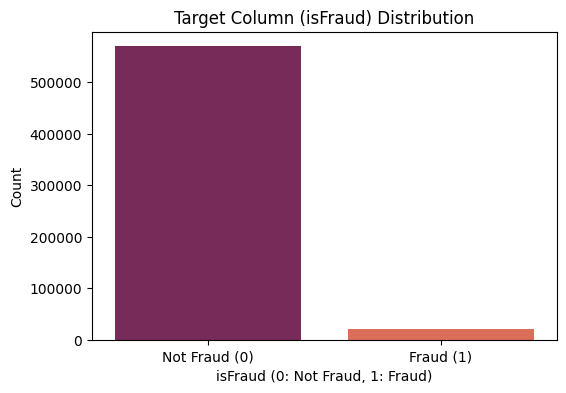

In [ ]:
plt.figure(figsize=(6, 4))
sns.barplot(x=fraud_counts.index, y=fraud_counts.values, palette='rocket')
plt.title('Target Column (isFraud) Distribution')
plt.xlabel('isFraud (0: Not Fraud, 1: Fraud)')
plt.ylabel('Count')
plt.xticks([0, 1], ['Not Fraud (0)', 'Fraud (1)'])
plt.show()

In [ ]:
print("Starting data encoding and standardization...")

# 1. Separate target variable and prepare data for processing
if 'isFraud' in train.columns:
    y_train = train['isFraud']
    X_train = train.drop(['isFraud'], axis=1)
else:
    print("Error: 'isFraud' column not found in train DataFrame. Cannot proceed with target separation.")
    raise ValueError("'isFraud' column not found in train DataFrame.")

# Drop the main TransactionID from X_train as it's an identifier and shouldn't be a feature
if 'TransactionID' in X_train.columns:
    X_train = X_train.drop('TransactionID', axis=1)

# Identify other ID columns (e.g., from merges) to drop
id_cols_to_drop = ['TransactionID_x', 'TransactionID_y']
X_train = X_train.drop(columns=[col for col in id_cols_to_drop if col in X_train.columns], errors='ignore')

print(f"X_train shape after initial drops: {X_train.shape}")

# 2. Identify categorical and numerical features for processing
# These lists will be used for imputation.
numerical_cols_initial = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols_initial = X_train.select_dtypes(include='object').columns.tolist() # 'object' type for strings

print(f"Number of initial numerical columns: {len(numerical_cols_initial)}")
print(f"Number of initial categorical columns: {len(categorical_cols_initial)}")

# 3. Apply imputation and encoding/scaling
print("Applying imputation, encoding, and scaling...")

# Imputation for numerical features
if numerical_cols_initial:
    # Explicitly replace inf values with NaN for numerical columns before imputation
    print("Replacing infinity values with NaN in initial numerical columns column by column...")
    for col in numerical_cols_initial:
        X_train.loc[np.isinf(X_train[col]), col] = np.nan
    print("Infinity values replaced with NaN in initial numerical columns.")

    numerical_imputer = SimpleImputer(strategy='median')
    X_train[numerical_cols_initial] = numerical_imputer.fit_transform(X_train[numerical_cols_initial])
    print(f"Initial numerical features imputed for {len(numerical_cols_initial)} columns.")
else:
    print("No initial numerical columns to impute.")

# Imputation and Encoding for categorical features
if categorical_cols_initial:
    # First, fill NaNs in categorical columns with a placeholder
    for col in categorical_cols_initial:
        X_train[col] = X_train[col].astype(str)

    categorical_imputer = SimpleImputer(strategy='constant', fill_value='missing')
    X_train[categorical_cols_initial] = categorical_imputer.fit_transform(X_train[categorical_cols_initial])

    # Then, encode categorical features using LabelEncoder
    for col in categorical_cols_initial:
        le = LabelEncoder()
        le.fit(X_train[col])
        X_train[col] = le.transform(X_train[col])
    print(f"Categorical features imputed and LabelEncoded for {len(categorical_cols_initial)} columns.")
else:
    print("No categorical columns to impute or encode.")

# After all imputation and encoding, all features in X_train should be numerical.
# Now, apply StandardScaler to ALL columns in X_train.
final_numerical_cols = X_train.select_dtypes(include=np.number).columns.tolist()
if final_numerical_cols:
    scaler = StandardScaler()
    X_train[final_numerical_cols] = scaler.fit_transform(X_train[final_numerical_cols])
    print(f"All {len(final_numerical_cols)} features in X_train standardized using StandardScaler.")
else:
    print("No numerical columns found in X_train for final standardization.")

print("Data preparation completed: all features standardized, categorical features encoded, and missing values handled.")
print(f"Final X_train shape: {X_train.shape}")

print("\nX_train head after full processing:")
display(X_train.head())


Starting data encoding and standardization...
X_train shape after initial drops: (590540, 456)
Number of initial numerical columns: 416
Number of initial categorical columns: 40
Applying imputation, encoding, and scaling...
Replacing infinity values with NaN in initial numerical columns column by column...
Infinity values replaced with NaN in initial numerical columns.
Initial numerical features imputed for 416 columns.
Categorical features imputed and LabelEncoded for 40 columns.
All 456 features in X_train standardized using StandardScaler.
Data preparation completed: all features standardized, categorical features encoded, and missing values handled.
Final X_train shape: (590540, 456)

X_train head after full processing:


,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,D1,D2,...,screen_height,TransactionAmt_Log,TransactionAmt_decimal,Transaction_day_of_week,Transaction_hour,id_02__id_20,id_02__D8,D11__DeviceInfo,DeviceInfo__P_emaildomain,P_emaildomain__C2,card2__dist1,card1__card5,card2__id_20,card5__P_emaildomain,addr1__card1,card1_count_full,card2_count_full,card3_count_full,card4_count_full,card5_count_full,card6_count_full,id_36_count_full,id_01_count_dist,id_31_count_dist,id_33_count_dist,id_36_count_dist,P_emaildomain_bin,P_emaildomain_suffix,R_emaildomain_bin,R_emaildomain_suffix
0,-1.577987,-0.278167,0.547250,0.821695,-0.009783,-0.281425,-2.187837,-1.396380,-1.675109,0.243321,0.069833,-0.138579,0.443858,0.336166,-0.098020,-0.092260,-0.037493,-0.059438,-0.21606,-0.112869,-0.046146,-0.053939,-0.208712,-0.054826,-0.087363,-0.047034,-0.243806,-0.147247,-0.508743,-0.285238,...,0.325846,-0.143632,0.278198,-1.455198,-1.822224,0.466874,0.466619,-1.061630,0.313074,0.704327,1.553372,-0.890125,1.586707,-1.269677,0.072709,-0.671361,-0.516893,0.36406,-2.921706,-1.321168,-1.693678,0.557347,0.565484,0.558088,0.376387,0.557347,0.278335,1.786051,0.197002,0.521488
1,-1.577986,-0.443327,0.547250,-1.457558,0.264810,-0.281425,-1.222461,-2.368254,-1.675109,0.347543,0.069833,-0.183967,-0.524573,0.336166,-0.098020,-0.092260,-0.037493,-0.059438,-0.21606,-0.112869,-0.046146,-0.053939,-0.268682,-0.054826,-0.097964,-0.047034,-0.243806,-0.147247,-0.597605,-0.285238,...,0.325846,-1.044581,-0.873982,-1.455198,-1.822224,0.466874,0.466619,1.164934,0.291261,-0.793415,0.192655,0.241985,0.198456,-2.328223,0.265992,-0.498512,-0.848063,0.36406,-1.172086,-1.096984,-1.693678,0.557347,0.565484,0.558088,0.376387,0.557347,-0.590595,-0.507924,0.197002,0.521488
2,-1.577972,-0.317889,0.547250,-1.068263,0.813997,-0.281425,0.708291,-0.813255,0.549374,0.399654,0.069833,0.967246,0.685966,0.336166,-0.098020,-0.092260,-0.037493,-0.059438,-0.21606,-0.112869,-0.046146,-0.053939,-0.208712,-0.054826,-0.097964,-0.047034,-0.243806,-0.147247,-0.597605,-0.285238,...,0.325846,-0.300121,-0.873982,-1.455198,-1.822224,0.466874,0.466619,-0.868586,0.318527,0.961311,0.695300,0.609339,0.725099,-0.739104,0.480713,-0.383729,1.129208,0.36406,0.701966,-0.878967,0.584030,0.557347,0.565484,0.558088,0.376387,0.557347,-0.156130,-0.507924,0.197002,0.521488
3,-1.577965,-0.355521,0.547250,1.679858,1.305711,-0.281425,-1.222461,-2.003802,0.549374,1.921291,0.069833,-0.183967,1.775451,0.336166,-0.090533,-0.066398,-0.037493,-0.059438,-0.21606,-0.070916,-0.046146,-0.053939,-0.208712,-0.054826,-0.097964,-0.047034,-0.058284,-0.147247,0.113291,-0.172822,...,0.325846,-0.473610,-0.873982,-1.455198,-1.822224,0.466874,0.466619,1.164934,0.341703,1.677244,1.374683,0.007488,1.389862,-2.042130,1.217943,0.453779,-0.674448,0.36406,-1.172086,-1.121589,0.584030,0.557347,0.565484,0.558088,0.376387,0.557347,1.581732,-0.507924,0.197002,0.521488
4,-1.577964,-0.355521,-1.559603,-1.102133,0.967258,-0.281425,-1.222461,-2.368254,-1.675109,1.337649,0.069833,-0.183967,-0.524573,0.336166,-0.098020,-0.092260,-0.037493,-0.059438,-0.21606,-0.112869,-0.046146,-0.043454,-0.268682,-0.044364,-0.097964,-0.047034,-0.243806,-0.147247,-0.597605,-0.285238,...,-3.764375,-0.473610,-0.873982,-1.455198,-1.822224,-0.144096,-0.136041,0.426494,-3.055661,-0.793415,0.957871,0.579294,0.859931,-2.328223,0.785452,-0.678113,-0.200881,0.36406,-1.172086,-1.096984,-1.693678,-1.731920,-1.938195,-1.832831,-2.693781,-1.731920,-0.590595,-0.507924,0.197002,0.521488


In [ ]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np
import pandas as pd

# Explanation:
# The reason some standardized values were below 1 and higher than 1 is because
# StandardScaler, which was previously applied, transforms data to have a mean of 0
# and a standard deviation of 1. It does not bound the values to a specific range.
# For example, if a feature has outliers or a wide distribution, its standardized values
# can easily fall outside the [-1, 1] range.

# To scale values strictly between 0 and 1, you should use MinMaxScaler.
# MinMaxScaler transforms features by scaling each feature to a given range,
# typically [0, 1], using the formula: X_scaled = (X - X_min) / (X_max - X_min).

print("Applying MinMaxScaler to scale X_train features between 0 and 1...")

# Initialize MinMaxScaler
scaler = MinMaxScaler()

# Identify numerical columns in X_train (all columns should be numerical at this stage after preprocessing)
# Based on previous cells, all columns should be numerical after LabelEncoding categorical features.
numerical_cols = X_train.select_dtypes(include=np.number).columns.tolist()

if numerical_cols:
    # Apply MinMaxScaler to the X_train DataFrame
    X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
    print(f"All {len(numerical_cols)} features in X_train scaled to [0, 1] using MinMaxScaler.")
else:
    print("No numerical columns found in X_train for MinMaxScaler application.")

print("\nX_train head after Min-Max scaling:")
display(X_train.head())

print("\nDescriptive statistics for a few scaled columns to illustrate the [0, 1] range:")
numerical_cols_display = X_train.select_dtypes(include=np.number).columns.tolist()[:5]
if numerical_cols_display:
    display(X_train[numerical_cols_display].describe())
else:
    print("No numerical columns found in X_train to display.")

# Important Note:
# X_train was previously scaled using StandardScaler in an earlier step.
# This current operation applies MinMaxScaler *on top of* the already StandardScaler-transformed data.
# If you intended to choose *between* StandardScaler and MinMaxScaler for the initial scaling,
# it would be more appropriate to modify the cell (ID: 6c873ba8-03e4-4cd0-9956-2fa003ba0119)
# where StandardScaler was first applied, and replace it with MinMaxScaler there.
# This approach ensures the data is scaled only once from its raw (imputed/encoded) state.

Applying MinMaxScaler to scale X_train features between 0 and 1...
All 456 features in X_train scaled to [0, 1] using MinMaxScaler.

X_train head after Min-Max scaling:


,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,D1,D2,...,screen_height,TransactionAmt_Log,TransactionAmt_decimal,Transaction_day_of_week,Transaction_hour,id_02__id_20,id_02__D8,D11__DeviceInfo,DeviceInfo__P_emaildomain,P_emaildomain__C2,card2__dist1,card1__card5,card2__id_20,card5__P_emaildomain,addr1__card1,card1_count_full,card2_count_full,card3_count_full,card4_count_full,card5_count_full,card6_count_full,id_36_count_full,id_01_count_dist,id_31_count_dist,id_33_count_dist,id_36_count_dist,P_emaildomain_bin,P_emaildomain_suffix,R_emaildomain_bin,R_emaildomain_suffix
0,0.000000e+00,0.002137,1.00,0.743044,0.522,0.381679,0.25,0.306569,0.25,0.488636,0.836957,0.001847,0.542373,0.533333,0.000213,0.000176,0.0,0.0,0.0,0.000444,0.0,0.0000,0.004762,0.000000,0.000627,0.0,0.000343,0.0007,0.021875,0.151562,...,1.000000,0.477218,0.500501,0.0,0.0,1.00000,1.000000,0.017059,0.940643,0.673198,0.988734,0.250895,1.000000,0.328666,0.536737,0.002813,0.182314,1.0,0.013241,0.000931,0.33863,1.00000,1.000000,1.000000,1.00000,1.00000,0.666667,0.75,0.666667,0.75
1,6.359409e-08,0.000900,1.00,0.100885,0.608,0.381679,0.50,0.014599,0.25,0.511364,0.836957,0.000778,0.271186,0.533333,0.000213,0.000176,0.0,0.0,0.0,0.000444,0.0,0.0000,0.000000,0.000000,0.000314,0.0,0.000343,0.0007,0.000000,0.151562,...,1.000000,0.404089,0.000000,0.0,0.0,1.00000,1.000000,0.982128,0.937618,0.237252,0.579431,0.582966,0.575309,0.028740,0.592225,0.045677,0.062182,1.0,0.489679,0.098144,0.33863,1.00000,1.000000,1.000000,1.00000,1.00000,0.444444,0.00,0.666667,0.75
2,4.387992e-06,0.001840,1.00,0.210566,0.780,0.381679,1.00,0.481752,0.50,0.522727,0.836957,0.027902,0.610169,0.533333,0.000213,0.000176,0.0,0.0,0.0,0.000444,0.0,0.0000,0.004762,0.000000,0.000314,0.0,0.000343,0.0007,0.000000,0.151562,...,1.000000,0.464516,0.000000,0.0,0.0,1.00000,1.000000,0.100731,0.941399,0.747998,0.730626,0.690719,0.736419,0.478998,0.653866,0.074141,0.779440,1.0,1.000000,0.192682,1.00000,1.00000,1.000000,1.000000,1.00000,1.00000,0.555556,0.00,0.666667,0.75
3,6.295815e-06,0.001558,1.00,0.984824,0.934,0.381679,0.50,0.124088,0.50,0.854545,0.836957,0.000778,0.915254,0.533333,0.000427,0.000879,0.0,0.0,0.0,0.001775,0.0,0.0000,0.004762,0.000000,0.000314,0.0,0.008568,0.0007,0.175000,0.175000,...,1.000000,0.450434,0.000000,0.0,0.0,1.00000,1.000000,0.982128,0.944612,0.956384,0.934984,0.514183,0.939782,0.109801,0.865509,0.281830,0.125161,1.0,0.489679,0.087474,1.00000,1.00000,1.000000,1.000000,1.00000,1.00000,1.000000,0.00,0.666667,0.75
4,6.740974e-06,0.001558,0.25,0.201023,0.828,0.381679,0.50,0.014599,0.25,0.727273,0.836957,0.000778,0.271186,0.533333,0.000213,0.000176,0.0,0.0,0.0,0.000444,0.0,0.0003,0.000000,0.000307,0.000314,0.0,0.000343,0.0007,0.000000,0.151562,...,0.086957,0.450434,0.000000,0.0,0.0,0.84364,0.845318,0.662063,0.473535,0.237252,0.809608,0.681906,0.777666,0.028740,0.741350,0.001139,0.296948,1.0,0.489679,0.098144,0.33863,0.28725,0.043813,0.002354,0.00105,0.28725,0.444444,0.00,0.666667,0.75



Descriptive statistics for a few scaled columns to illustrate the [0, 1] range:


,TransactionDT,TransactionAmt,ProductCD,card1,card2
count,590540.000000,590540.000000,590540.000000,590540.000000,590540.000000
mean,0.463341,0.004220,0.805189,0.511539,0.525064
std,0.293628,0.007489,0.355982,0.281741,0.313191
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.187008,0.001349,0.750000,0.288515,0.230000
50%,0.459157,0.002145,1.000000,0.498850,0.522000
75%,0.709724,0.003906,1.000000,0.757875,0.824000
max,1.000000,1.000000,1.000000,1.000000,1.000000


In [ ]:
def reduce_mem_usage(df):
    """ iterate through all the columns of a dataframe and modify the data type
        to reduce memory usage.
    """
    start_mem = df.memory_usage().sum() / 1024**2
    print('Memory usage of dataframe is {:.2f} MB'.format(start_mem))

    for col in df.columns:
        col_type = df[col].dtype

        if col_type != object:
            c_min = df[col].min()
            c_max = df[col].max()
            if str(col_type)[:3] == 'int':
                if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                    df[col] = df[col].astype(np.int8)
                elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                    df[col] = df[col].astype(np.int16)
                elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                    df[col] = df[col].astype(np.int32)
                elif c_min > np.iinfo(np.int64).min and c_max < np.iinfo(np.int64).max:
                    df[col] = df[col].astype(np.int64)
            else:
                if c_min > np.finfo(np.float16).min and c_max < np.finfo(np.float16).max:
                    df[col] = df[col].astype(np.float16)
                elif c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                    df[col] = df[col].astype(np.float32)
                else:
                    df[col] = df[col].astype(np.float64)
        else:
            # Handle categorical features, ensure they are not numerical (already processed by LabelEncoder)
            # If there are any object columns left, convert them to category
            if df[col].dtype == 'object': # Check again if it's still an object type
                df[col] = df[col].astype('category')

    end_mem = df.memory_usage().sum() / 1024**2
    print('Memory usage after optimization is: {:.2f} MB'.format(end_mem))
    print('Decreased by {:.1f}%'.format(100 * (start_mem - end_mem) / start_mem))

    return df

print("Applying memory reduction to X_train")

X_train = reduce_mem_usage(X_train)

print("Memory reduction complete for X_train and test.")


Applying memory reduction to X_train
Memory usage of dataframe is 2054.49 MB
Memory usage after optimization is: 513.62 MB
Decreased by 75.0%
Memory reduction complete for X_train and test.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

from xgboost import XGBClassifier

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

In [ ]:
from scipy.stats import randint, loguniform, uniform

RANDOM_STATE = 42


X = X_train.copy()
y = y_train.copy()

print("Feature data shape:", X.shape)
print("Target data shape:", y.shape)
print("Fraud rate:", round(y.mean() * 100, 3), "%")

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,stratify=y,random_state=RANDOM_STATE)
print("Dataset Shape:", X.shape)
print("Training Data Shape:", X_train.shape)
print("Test Data Shape:", X_test.shape)

print("\\nTraining fraud rate:", round(y_train.mean() * 100, 3), "%")
print("Test fraud rate:", round(y_test.mean() * 100, 3), "%")



Feature data shape: (590540, 456)
Target data shape: (590540,)
Fraud rate: 3.499 %
Dataset Shape: (590540, 456)
Training Data Shape: (472432, 456)
Test Data Shape: (118108, 456)
\nTraining fraud rate: 3.499 %
Test fraud rate: 3.499 %


In [ ]:
base_pipeline = Pipeline(
    [
        (
            "model",
            DecisionTreeClassifier(
                random_state=RANDOM_STATE
            )
        )
    ]
)
base_pipeline.fit(X_train, y_train)

y_base_train_pred = base_pipeline.predict(X_train)
y_base_test_pred = base_pipeline.predict(X_test)

base_train_acc = round(accuracy_score(y_train, y_base_train_pred) * 100,2)
base_test_acc = round(accuracy_score(y_test, y_base_test_pred) * 100,2)

print("Baseline Train Accuracy:", base_train_acc)
print("Baseline Test Accuracy:", base_test_acc)

print("Train - Classification Report")
print(classification_report(y_train,y_base_train_pred,digits=4))

print("Test - Classification Report")
print(classification_report( y_test,y_base_test_pred,digits=4))



Baseline Train Accuracy: 100.0
Baseline Test Accuracy: 96.91
Train - Classification Report
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000    455902
           1     1.0000    1.0000    1.0000     16530

    accuracy                         1.0000    472432
   macro avg     1.0000    1.0000    1.0000    472432
weighted avg     1.0000    1.0000    1.0000    472432

Test - Classification Report
              precision    recall  f1-score   support

           0     0.9859    0.9821    0.9840    113975
           1     0.5534    0.6121    0.5813      4133

    accuracy                         0.9691    118108
   macro avg     0.7696    0.7971    0.7826    118108
weighted avg     0.9707    0.9691    0.9699    118108



**Note:** Accuracy is not sufficient for this dataset because the fraud class is highly imbalanced. PR-AUC is therefore used as the main model-selection metric.

In [ ]:
# PR-AUC - training data
y_train_prob = base_pipeline.predict_proba(X_train)[:, 1]
print("Training Average Precision Score:",round(average_precision_score(y_train,y_train_prob),4))


# PR-AUC - test data
y_test_prob = base_pipeline.predict_proba(X_test)[:, 1]
print("Test Average Precision Score:",round(average_precision_score(y_test,y_test_prob),4))

Training Average Precision Score: 1.0
Test Average Precision Score: 0.3523


In [ ]:
# 5-fold stratified cross-validation
k = 5
cv = StratifiedKFold(n_splits=k,shuffle=True,random_state=RANDOM_STATE)

In [ ]:
# calculate class imbalance ratio using only the training portion

num_negative = int((y_train == 0).sum())
num_positive = int((y_train == 1).sum())

scale_pos_weight_value = (num_negative / max(num_positive, 1))

print("Negative training samples:", num_negative)
print("Positive training samples:", num_positive)
print("scale_pos_weight:",round(scale_pos_weight_value, 2))

Negative training samples: 455902
Positive training samples: 16530
scale_pos_weight: 27.58


In [ ]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
!pip install catboost
from catboost import CatBoostClassifier
classification_models = {
    "rf_cost_sensitive": Pipeline([

        ("model", RandomForestClassifier(
            random_state=42,
            class_weight="balanced_subsample",
            n_jobs=-1
        ))
    ]),

    "xgb_cost_sensitive": Pipeline([

        ("model", XGBClassifier(
            objective='binary:logistic',
            eval_metric='logloss',
            scale_pos_weight=scale_pos_weight_value,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "lgbm_cost_sensitive": Pipeline([

        ("model", LGBMClassifier(
            objective='binary',
            metric='auc',
            scale_pos_weight=scale_pos_weight_value,
            random_state=42,
            n_jobs=-1,
            verbose=-1
        ))
    ]),

    "catboost_cost_sensitive": Pipeline([

        ("model", CatBoostClassifier(
            iterations=300,
            learning_rate=0.08,
            depth=6,
            auto_class_weights='Balanced',
            eval_metric='AUC',
            random_seed=42,
            verbose=0,
            thread_count=-1
        ))
    ])
}

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 26.6 MB/s eta 0:00:00


In [ ]:
# compare models using PR-AUC across the same five folds

model_cv_results = {}

for name, model in classification_models.items():

    pr_auc_scores = []

    print("\\nModel:", name)

    for fold, (tr_idx, val_idx) in enumerate(
        cv.split(X_train, y_train),
        start=1
    ):

        X_tr = X_train.iloc[tr_idx]
        X_val = X_train.iloc[val_idx]

        y_tr = y_train.iloc[tr_idx]
        y_val = y_train.iloc[val_idx]

        model.fit(X_tr, y_tr)

        pred_prob = model.predict_proba(X_val)[:, 1]

        fold_pr_auc = average_precision_score(
            y_val,
            pred_prob
        )

        pr_auc_scores.append(fold_pr_auc)

        print(
            f"Fold {fold} PR-AUC:",
            round(fold_pr_auc, 4)
        )

    mean_pr_auc = float(np.mean(pr_auc_scores))
    std_pr_auc = float(np.std(pr_auc_scores))

    model_cv_results[name] = {
        "PR-AUC values": pr_auc_scores,
        "CV PR-AUC mean": mean_pr_auc,
        "CV PR-AUC std": std_pr_auc
    }

    print(
        "CV PR-AUC mean:",
        round(mean_pr_auc, 4)
    )

    print(
        "CV PR-AUC std:",
        round(std_pr_auc, 4)
    )

\nModel: rf_cost_sensitive
Fold 1 PR-AUC: 0.7302
Fold 2 PR-AUC: 0.7359
Fold 3 PR-AUC: 0.7341
Fold 4 PR-AUC: 0.7295
Fold 5 PR-AUC: 0.7439
CV PR-AUC mean: 0.7347
CV PR-AUC std: 0.0052
\nModel: xgb_cost_sensitive
Fold 1 PR-AUC: 0.6964
Fold 2 PR-AUC: 0.6967
Fold 3 PR-AUC: 0.6986
Fold 4 PR-AUC: 0.6928
Fold 5 PR-AUC: 0.7122
CV PR-AUC mean: 0.6994
CV PR-AUC std: 0.0067
\nModel: lgbm_cost_sensitive
Fold 1 PR-AUC: 0.623
Fold 2 PR-AUC: 0.6185
Fold 3 PR-AUC: 0.6235
Fold 4 PR-AUC: 0.6102
Fold 5 PR-AUC: 0.6342
CV PR-AUC mean: 0.6218
CV PR-AUC std: 0.0078
\nModel: catboost_cost_sensitive
Fold 1 PR-AUC: 0.6059
Fold 2 PR-AUC: 0.6066
Fold 3 PR-AUC: 0.6125
Fold 4 PR-AUC: 0.5958
Fold 5 PR-AUC: 0.6202
CV PR-AUC mean: 0.6082
CV PR-AUC std: 0.0081


In [ ]:
# model selection summary

cv_summary = pd.DataFrame(
    {
        name: {
            "CV PR-AUC Mean": values["CV PR-AUC mean"],
            "CV PR-AUC Std": values["CV PR-AUC std"]
        }
        for name, values in model_cv_results.items()
    }
).T.sort_values(
    "CV PR-AUC Mean",
    ascending=False
)

display(
    cv_summary.round(4)
)

,CV PR-AUC Mean,CV PR-AUC Std
rf_cost_sensitive,0.7347,0.0052
xgb_cost_sensitive,0.6994,0.0067
lgbm_cost_sensitive,0.6218,0.0078
catboost_cost_sensitive,0.6082,0.0081


**Best Model as per model selection process:** RandomForestClassifier


In [34]:
rfc_pipeline = classification_models["rf_cost_sensitive"]

In [41]:
# Expanded hyperparameter grid targeted for imbalanced datasets
param_dist = {
    "model__max_depth": [15, 30, None],
    "model__min_samples_leaf": [1, 5]
}

In [42]:
# Run RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=rfc_pipeline,
    param_distributions=param_dist,
    n_iter=6,                       # Only 6 combinations total
    scoring="average_precision",    # PR-AUC - good for imbalanced data
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=1
)

In [43]:
random_search.fit(X_train, y_train)

print("\n--- Hyperparameter Tuning Results ---")
print("Best CV PR-AUC:", round(random_search.best_score_, 4))
print("Best Params:", random_search.best_params_)

best_rfc_model = random_search.best_estimator_

Fitting 5 folds for each of 6 candidates, totalling 30 fits

--- Hyperparameter Tuning Results ---
Best CV PR-AUC: 0.7347
Best Params: {'model__min_samples_leaf': 1, 'model__max_depth': None}


**Re-train with best parameters**

In [44]:
best_rfc = Pipeline(
    [
        ("model", RandomForestClassifier(
            n_estimators=500,
            min_samples_leaf=1,
            max_features="log2",
            max_depth=30,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            class_weight="balanced_subsample"
        ))
    ]
)

In [45]:
# train best rfc
best_rfc.fit(X_train, y_train)

Pipeline(steps=[('model',
                 RandomForestClassifier(class_weight='balanced_subsample',
                                        max_depth=30, max_features='log2',
                                        n_estimators=500, n_jobs=-1,
                                        random_state=42))])

**Model Evaluation**

In [46]:
# training data prediction
y_train_pred = best_rfc.predict(X_train)

In [47]:
train_acc = accuracy_score(y_train, y_train_pred)
print(f"Training Accuracy: {round(train_acc*100, 2)} %")

Training Accuracy: 99.61 %


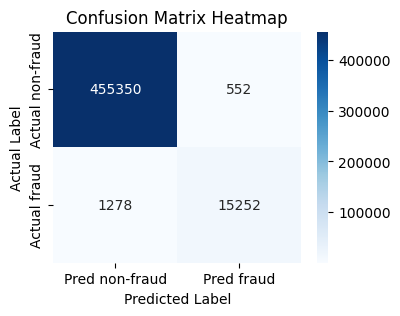

In [48]:
# confusion matrix
cm = confusion_matrix(y_train, y_train_pred)

plt.figure(figsize=(4,3))
# heatmap
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred non-fraud", "Pred fraud"],
    yticklabels=["Actual non-fraud", "Actual fraud"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix Heatmap")
plt.show()

In [49]:
print("Training Classification report")
print(classification_report(y_train, y_train_pred))

Training Classification report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    455902
           1       0.97      0.92      0.94     16530

    accuracy                           1.00    472432
   macro avg       0.98      0.96      0.97    472432
weighted avg       1.00      1.00      1.00    472432



In [50]:
train_proba = best_rfc.predict_proba(X_train)[:, 1]
print("Train PR-AUC:", round(average_precision_score(y_train, train_proba), 4))

Train PR-AUC: 0.9813


In [51]:
# test data prediction
y_test_pred = best_rfc.predict(X_test)

In [52]:
test_acc = accuracy_score(y_test, y_test_pred)
print(f"Test Accuracy: {round(test_acc*100, 2)} %")

Test Accuracy: 97.8 %


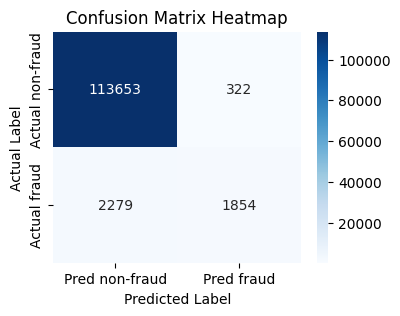

In [53]:
# confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(4,3))
# heatmap
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred non-fraud", "Pred fraud"],
    yticklabels=["Actual non-fraud", "Actual fraud"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix Heatmap")
plt.show()

In [54]:
print("Test Classification report")
print(classification_report(y_test, y_test_pred))

Test Classification report
              precision    recall  f1-score   support

           0       0.98      1.00      0.99    113975
           1       0.85      0.45      0.59      4133

    accuracy                           0.98    118108
   macro avg       0.92      0.72      0.79    118108
weighted avg       0.98      0.98      0.97    118108



In [55]:
test_proba = best_rfc.predict_proba(X_test)[:, 1]
print("Test PR-AUC:", round(average_precision_score(y_test, test_proba), 4))

Test PR-AUC: 0.6377
